# Sesión 2 · Notebook 4 · Plantilla renovada

**Mentoría Quant · Fuera de Muestra · Castle Capital**

El framework de la semana en un solo notebook, listo para **cada idea nueva**. Ahora **cada prueba queda guardada en tu Google Drive** junto con un índice de todas tus hipótesis.

**Cómo usarlo**
1. Haz una copia por cada hipótesis (*Archivo → Guardar una copia en Drive*).
2. Edita **solo** las celdas marcadas con ✏️: carpeta, datos, hipótesis, condición y variable futura.
3. Ejecuta todo en orden. Colab te pedirá permiso para conectar Drive. El candado de la prueba se abre **una sola vez**.

| Paso | Celda | Qué hace |
|---|---|---|
| 0 | Motor | Funciones de validación (no se edita) |
| 0b | ✏️ Carpeta en Drive | Dónde quedan guardadas tus pruebas |
| 1 | ✏️ Datos | NASDAQ 1999–2018 incluido, o cualquier ticker de Yahoo |
| 2 | ✏️ Hipótesis | Las tres piezas, el criterio de rechazo y las fechas |
| 3 | ✏️ Condición y variable futura | Dos funciones de Python |
| 4 | Pre-registro y regla de oro | Huella digital y prueba de no anticipación |
| 5 | Construcción | Medición, prueba del azar, variantes con bitácora y Holm |
| 6 | ¿Alcanzan los datos? | Efecto mínimo detectable en prueba |
| 7 | Candado y veredicto | El examen, una vez |
| 8 | Ficha e índice | La hipótesis en una página, guardada en Drive |
| 9 | Tu repositorio | Todas las hipótesis que has probado |

**Lo que queda en tu Drive** (`Mi unidad/Mentoria_Quant/hipotesis/`):

| Archivo | Para qué sirve |
|---|---|
| `indice_hipotesis.csv` | Una fila por idea: veredicto, diferencias, p, MDE. Ábrelo con Google Sheets |
| `preregistro_<id>.json` | La hipótesis con fecha y huella: demuestra que no la cambiaste |
| `bitacora_<id>.csv` | Todas las variantes que probaste en construcción |
| `apertura_<id>.json` | Cuándo abriste la prueba (el candado) |
| `ficha_<id>.txt` | La ficha final |

El ejemplo que viene cargado es una idea nueva: *"cuando el índice cierra en la parte baja del rango del día, comprar al cierre rinde más al día siguiente"* (IBS bajo). Reemplázala por la tuya.

> ¿Prefieres no copiar el motor? Todo esto también está en la librería: `%pip install git+https://github.com/JuliRey2000/prueba-hipotesis.git`

## 0 · Motor (no editar)

In [1]:
# En Google Colab esta línea instala lo necesario (tarda unos segundos)
%pip install -q arch statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from arch.data import nasdaq          # datos diarios reales del NASDAQ Composite, 1999–2018

plt.rcParams.update({
    'figure.figsize': (9, 4), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.alpha': 0.25, 'font.size': 11,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})
AZUL, NARANJA, GRIS, ROJO, NAVY = '#2a78d6', '#eb6834', '#8a8a86', '#e34948', '#14355F'

import json, hashlib, os
from datetime import datetime
from statsmodels.stats.multitest import multipletests


# ---------- Datos ----------
def cargar_datos(fuente='arch', ticker='^IXIC', inicio='1999-01-01'):
    """NASDAQ Composite 1999–2018 (librería arch) o cualquier ticker diario de Yahoo Finance."""
    if fuente == 'arch':
        return nasdaq.load()[['Open', 'High', 'Low', 'Close']]
    import yfinance as yf
    df = yf.download(ticker, start=inicio, auto_adjust=False, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[['Open', 'High', 'Low', 'Close']].dropna()
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    if len(df) < 500:
        raise ValueError('Muy pocos datos: revisa el ticker o la conexión')
    return df


# ---------- Bloques para construir variables futuras ----------
def atr(df, n=14):
    """Rango verdadero medio de los últimos n días, hasta hoy."""
    C, H, L = df['Close'], df['High'], df['Low']
    rv = pd.concat([H - L, (H - C.shift(1)).abs(), (L - C.shift(1)).abs()], axis=1).max(axis=1)
    return rv.rolling(n).mean()

def resultado_regla_estudio(df, k_stop=1.0):
    """R de comprar al cierre de hoy, stop a k·ATR por debajo, salida al cierre de mañana (gap: sale en la apertura)."""
    C, L, O = df['Close'], df['Low'], df['Open']
    riesgo = k_stop * atr(df)
    stop = C - riesgo
    res = (C.shift(-1) - C) / riesgo
    toca = L.shift(-1) <= stop
    return res.where(~toca, (np.minimum(O.shift(-1), stop) - C) / riesgo).round(10)


# ---------- Pre-registro y regla de oro ----------
def huella(h):
    return hashlib.sha256(json.dumps(h, ensure_ascii=False, sort_keys=True, default=str).encode('utf-8')).hexdigest()

def preregistrar(h):
    archivo = f"preregistro_{h['id']}.json"
    if os.path.exists(archivo):
        previo = json.load(open(archivo, encoding='utf-8'))
        estado = '✓ sin cambios' if previo['huella'] == huella(h) else '✗ LA HIPÓTESIS CAMBIÓ desde el registro'
        print(f"Ya registrada el {previo['fecha']}: {estado}")
        return previo
    registro = {'fecha': datetime.now().isoformat(timespec='seconds'), 'huella': huella(h), 'hipotesis': h}
    json.dump(registro, open(archivo, 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=str)
    print(f"Registrada el {registro['fecha']}   ·   huella: {registro['huella']}")
    return registro

def mira_el_futuro(funcion, df, n_fechas=150, semilla=1, **params):
    completo = funcion(df, **params)
    fechas = np.random.default_rng(semilla).choice(df.index[60:-30], n_fechas, replace=False)
    for f in fechas:
        a, b = completo.loc[f], funcion(df.loc[:f], **params).loc[f]
        if not (a == b or (pd.isna(a) and pd.isna(b))):
            return True
    return False


# ---------- Medición ----------
def armar_tabla(df, params):
    """Una fila por día: si se cumplió la condición y el resultado en R."""
    t = pd.DataFrame({'cond': condicion(df, **params), 'R': resultado_R(df, **params)}).dropna()
    t['cond'] = t['cond'].astype(bool)
    return t

def medir(t, costo):
    con, sin = t.loc[t['cond'], 'R'], t.loc[~t['cond'], 'R']
    if len(con) < 2 or len(sin) < 2:
        raise ValueError('La condición casi nunca (o casi siempre) se cumple: no hay con qué comparar')
    dif = con.mean() - sin.mean()
    ee = np.sqrt(con.var() / len(con) + sin.var() / len(sin))
    return pd.Series({'casos con condición': len(con), 'casos sin condición': len(sin),
                      'E[R | condición]': con.mean(), 'E[R | sin condición]': sin.mean(),
                      'diferencia': dif, 'error estándar': ee,
                      'IC 95 % inferior': dif - 1.96 * ee, 'IC 95 % superior': dif + 1.96 * ee,
                      'esperanza neta': con.mean() - costo})

def prueba_permutacion(t, n=5000, semilla=0):
    rng = np.random.default_rng(semilla)
    r, marca = t['R'].to_numpy(), t['cond'].to_numpy().copy()
    real = r[marca].mean() - r[~marca].mean()
    azar = np.empty(n)
    for i in range(n):
        rng.shuffle(marca)
        azar[i] = r[marca].mean() - r[~marca].mean()
    return real, (1 + np.sum(azar >= real)) / (n + 1), azar

def grafico_azar(real, p, azar, titulo):
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    ax.hist(azar, bins=60, color=GRIS, edgecolor='white', linewidth=0.4, label='diferencias producidas por el azar')
    ax.axvline(real, color=NAVY, lw=2.5, label=f'diferencia real = {real:+.3f} R  (p = {p:.4f})')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.35); ax.set_xlabel('diferencia de esperanza (R)'); ax.set_title(titulo)
    ax.legend(frameon=False, loc='upper left', fontsize=9.5); plt.show()

def ver(x):
    fmt = lambda v: f'{v:,.0f}' if float(v).is_integer() and abs(v) >= 1 else f'{v:+.4f}'
    print(x.map(fmt).to_string())


# ---------- Candado y veredicto ----------
def abrir_candado(h):
    archivo = f"apertura_{h['id']}.json"
    if os.path.exists(archivo):
        print(f"⚠ La prueba ya se abrió el {json.load(open(archivo, encoding='utf-8'))['fecha']}. "
              "Si ajustaste algo después de mirarla, ya no es fuera de muestra.")
    else:
        json.dump({'fecha': datetime.now().isoformat(timespec='seconds'), 'huella': huella(h)},
                  open(archivo, 'w', encoding='utf-8'))

def veredicto(m, p, h):
    criterios = {f"diferencia ≥ {h['umbral_R']} R": m['diferencia'] >= h['umbral_R'],
                 f"p < {h['alfa']}": p < h['alfa'],
                 'esperanza neta > 0': m['esperanza neta'] > 0}
    for nombre, ok in criterios.items():
        print(f"  {'✓' if ok else '✗'} {nombre}")
    if m['diferencia'] <= 0 or m['esperanza neta'] <= 0:
        return 'RECHAZADA'
    return 'APOYADA (todavía no rechazada)' if all(criterios.values()) else 'NO CONCLUYENTE'

print('Motor listo.')

Note: you may need to restart the kernel to use updated packages.


Motor listo.


## 0b · ✏️ ¿Dónde se guardan tus pruebas?

Con `GUARDAR_EN_DRIVE = True` todo se guarda en tu Drive y **sobrevive aunque cierres Colab**: así el pre-registro y el candado funcionan de un día para otro.

**Carpeta compartida de la mentoría:** si el mentor te compartió la carpeta `Mentoria_Quant`, en Drive haz clic derecho → *Organizar → Agregar acceso directo → Mi unidad*. Con eso esta misma ruta apunta a la carpeta común. **Pon tu nombre en el `id`** de la hipótesis (por ejemplo `'julian_ibs_bajo'`) para no pisar los archivos de otros.

In [ ]:
GUARDAR_EN_DRIVE = True
CARPETA = '/content/drive/MyDrive/Mentoria_Quant/hipotesis'   # ✏️ cambia la ruta si quieres

if GUARDAR_EN_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:                       # fuera de Colab: carpeta local
        CARPETA = os.path.abspath('hipotesis')
    os.makedirs(CARPETA, exist_ok=True)
    os.chdir(CARPETA)                         # desde aquí, todos los archivos se guardan en esa carpeta

print('Guardando en:', os.getcwd())

## 1 · ✏️ Datos

- `'arch'`: NASDAQ Composite diario 1999–2018, igual para todos.
- `'yahoo'`: cualquier ticker diario (por ejemplo `'QQQ'`, `'^GSPC'`, `'EURUSD=X'`, `'GC=F'`). Requiere internet.

In [3]:
FUENTE = 'arch'          # 'arch' o 'yahoo'
TICKER = '^IXIC'         # solo se usa con 'yahoo'

datos = cargar_datos(FUENTE, TICKER)
print(f"{len(datos):,} días, de {datos.index[0]:%Y-%m-%d} a {datos.index[-1]:%Y-%m-%d}")

5,031 días, de 1999-01-04 a 2018-12-31


## 2 · ✏️ Tu hipótesis

Llena cada campo **antes** de mirar resultados. Las fechas de prueba deben ser **posteriores** a las de construcción. Si usas Yahoo, ajústalas a tus datos (por ejemplo, construcción hasta hace 3 años y prueba los últimos 3).

In [4]:
HIPOTESIS = {
    'id': 'ibs_bajo',                                       # nombre corto, sin espacios: se usa en los archivos
    'datos': 'NASDAQ Composite, velas diarias (librería arch)',
    'condicion': 'Hoy el índice cerró en la parte baja de su rango: IBS = (C − L) / (H − L) < ibs_max',
    'variable_futura': 'R de comprar al cierre de hoy, stop a 1,5·ATR(14), salida al cierre de mañana',
    'comparacion': 'La misma operación en los días con IBS normal o alto',
    'afirmacion': 'E[R | condición] − E[R | sin condición] >= umbral y esperanza neta > 0',
    'hipotesis_nula': 'H0: E[R | condición] − E[R | sin condición] <= 0',
    'umbral_R': 0.05,
    'costo_R': 0.02,
    'alfa': 0.05,
    'variantes': [{'ibs_max': 0.10, 'k_stop': 1.5}, {'ibs_max': 0.20, 'k_stop': 1.5}],   # cada variante es un ensayo
    'regla_de_eleccion': 'la de mayor diferencia en construcción',
    'construccion': ['1999-01-01', '2010-12-31'],
    'prueba': ['2011-01-01', '2018-12-31'],
}

## 3 · ✏️ Tu condición y tu variable futura

Dos funciones que reciben los precios (`Open`, `High`, `Low`, `Close`) y los parámetros de una variante:

- `condicion(df, **p)` → verdadero/falso por día, **solo con información hasta ese día**.
- `resultado_R(df, **p)` → el resultado en R de la operación abierta ese día. Puede usar `resultado_regla_estudio` o tu propia regla.

In [5]:
def condicion(df, **p):
    rango = df['High'] - df['Low']
    ibs = (df['Close'] - df['Low']) / rango.where(rango > 0)   # días sin rango quedan fuera (NaN → falso)
    return ibs < p['ibs_max']

def resultado_R(df, **p):
    return resultado_regla_estudio(df, k_stop=p['k_stop'])

## 4 · Pre-registro y regla de oro

In [6]:
registro = preregistrar(HIPOTESIS)

for v in HIPOTESIS['variantes']:
    falla = mira_el_futuro(condicion, datos, **v)
    print(f"Condición con {v}: {'✗ MIRA EL FUTURO: corrígela antes de seguir' if falla else '✓ solo usa información disponible'}")

Registrada el 2026-11-06T18:04:10   ·   huella: d6adcd3a0720bbb14aba6def71dfa6df6d1755e2c6cf06900e25782e90f92591


Condición con {'ibs_max': 0.1, 'k_stop': 1.5}: ✓ solo usa información disponible


Condición con {'ibs_max': 0.2, 'k_stop': 1.5}: ✓ solo usa información disponible


## 5 · Construcción

Se mide cada variante **solo** en construcción, se anota en la bitácora y se corrige por el número de variantes con Holm. Luego se elige con la regla escrita.

**Filtro antes de gastar el examen:** si la variante elegida no cumple el criterio ni siquiera en construcción (diferencia ≥ umbral, p de Holm < alfa y esperanza neta > 0), lo recomendable es archivarla y **no abrir la prueba**. Así esos datos siguen limpios para la próxima idea.

 ibs_max  k_stop  casos  diferencia  esperanza neta      p  p (Holm)
     0.1     1.5    559      0.0384          0.0229 0.0508    0.1016
     0.2     1.5    781      0.0130          0.0013 0.2723    0.2723

Variante elegida: {'ibs_max': 0.1, 'k_stop': 1.5}
casos con condición         559
casos sin condición       2,446
E[R | condición]        +0.0429
E[R | sin condición]    +0.0045
diferencia              +0.0384
error estándar          +0.0233
IC 95 % inferior        -0.0073
IC 95 % superior        +0.0840
esperanza neta          +0.0229


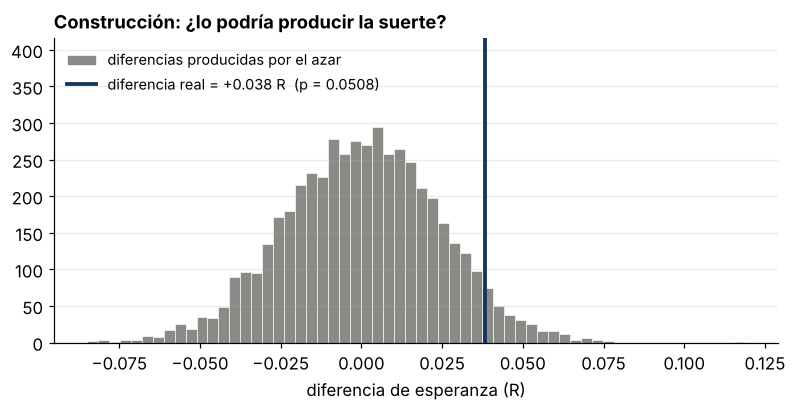

✗ No pasa ni en construcción: se recomienda archivarla y NO abrir la prueba.


In [7]:
FIN_C = HIPOTESIS['construccion'][1]
INI_P, FIN_P = HIPOTESIS['prueba']

filas = []
for v in HIPOTESIS['variantes']:
    t = armar_tabla(datos, v).loc[HIPOTESIS['construccion'][0]:FIN_C].iloc[:-1]     # embargo de 1 día
    m = medir(t, HIPOTESIS['costo_R'])
    real, p, _ = prueba_permutacion(t)
    filas.append({**v, 'casos': int(m['casos con condición']), 'diferencia': m['diferencia'],
                  'esperanza neta': m['esperanza neta'], 'p': p})

bitacora = pd.DataFrame(filas)
bitacora['p (Holm)'] = multipletests(bitacora['p'], method='holm')[1]
bitacora.to_csv(f"bitacora_{HIPOTESIS['id']}.csv", index=False)
print(bitacora.round(4).to_string(index=False))

elegida = HIPOTESIS['variantes'][int(bitacora['diferencia'].idxmax())]
construccion = armar_tabla(datos, elegida).loc[HIPOTESIS['construccion'][0]:FIN_C].iloc[:-1]
print(f"\nVariante elegida: {elegida}")
ver(medir(construccion, HIPOTESIS['costo_R']))
grafico_azar(*prueba_permutacion(construccion), 'Construcción: ¿lo podría producir la suerte?')

fila = bitacora.loc[bitacora['diferencia'].idxmax()]
PASA_CONSTRUCCION = bool((fila['diferencia'] >= HIPOTESIS['umbral_R']) and (fila['p (Holm)'] < HIPOTESIS['alfa'])
                         and (fila['esperanza neta'] > 0))
print('✓ Pasa en construcción: tiene sentido abrir la prueba.' if PASA_CONSTRUCCION else
      '✗ No pasa ni en construcción: se recomienda archivarla y NO abrir la prueba.')

## 6 · ¿Alcanzan los datos de prueba?

Solo se cuenta **cuántas veces** se cumple la condición en prueba; no se mira ningún resultado.

In [8]:
cond_prueba = condicion(datos, **elegida).loc[INI_P:FIN_P].iloc[:-1]
n_con, n_sin = int(cond_prueba.sum()), int((~cond_prueba).sum())
s_con = construccion.loc[construccion['cond'], 'R'].std()
s_sin = construccion.loc[~construccion['cond'], 'R'].std()
mde = 2.8 * np.sqrt(s_con**2 / n_con + s_sin**2 / n_sin)

print(f"Casos con condición en prueba: {n_con}")
print(f"Efecto mínimo detectable (80 %): {mde:.3f} R   ·   umbral escrito: {HIPOTESIS['umbral_R']:.3f} R")
if mde > HIPOTESIS['umbral_R']:
    print("La prueba no puede detectar un efecto del tamaño del umbral: un resultado tibio saldrá 'no concluyente'.")

Casos con condición en prueba: 213
Efecto mínimo detectable (80 %): 0.101 R   ·   umbral escrito: 0.050 R
La prueba no puede detectar un efecto del tamaño del umbral: un resultado tibio saldrá 'no concluyente'.


## 7 · Abrir el candado y veredicto

Una sola vez. Si la hipótesis cambió desde el registro, la celda lo dice. Si no pasó en construcción, la celda no abre la prueba salvo que pongas `ABRIR_DE_TODOS_MODOS = True` (solo para practicar).

In [9]:
ABRIR_DE_TODOS_MODOS = False      # ✏️ ponlo en True solo para practicar con una idea que no pasó

m_prueba = p_prueba = None
if PASA_CONSTRUCCION or ABRIR_DE_TODOS_MODOS:
    print('Hipótesis evaluada = registrada:', '✓' if huella(HIPOTESIS) == registro['huella'] else '✗ CAMBIÓ')
    abrir_candado(HIPOTESIS)
    prueba = armar_tabla(datos, elegida).loc[INI_P:FIN_P]
    m_prueba = medir(prueba, HIPOTESIS['costo_R'])
    real, p_prueba, azar = prueba_permutacion(prueba)
    ver(pd.DataFrame({'construcción': medir(construccion, HIPOTESIS['costo_R']), 'prueba': m_prueba}))
    grafico_azar(real, p_prueba, azar, 'Prueba: el examen de verdad')
    print(f"\nDiferencia en prueba: {m_prueba['diferencia']:+.4f} R   ·   p = {p_prueba:.4f}")
    VEREDICTO = veredicto(m_prueba, p_prueba, HIPOTESIS)
else:
    VEREDICTO = 'RECHAZADA EN CONSTRUCCIÓN (la prueba sigue sin abrir)'
print('VEREDICTO:', VEREDICTO)

VEREDICTO: RECHAZADA EN CONSTRUCCIÓN (la prueba sigue sin abrir)


## 8 · Ficha e índice (se guardan solos)

In [10]:
h = HIPOTESIS
texto_prueba = ('sin abrir' if m_prueba is None else
                f"diferencia {m_prueba['diferencia']:+.3f} R, p = {p_prueba:.4f}, esperanza neta {m_prueba['esperanza neta']:+.3f} R")
FICHA = f"""HIPÓTESIS: {h['id']}                Registrada: {registro['fecha']}   Huella: {registro['huella'][:16]}…

1. DATOS              {h['datos']}
2. CONDICIÓN          {h['condicion']}
3. VARIABLE FUTURA    {h['variable_futura']}
4. COMPARACIÓN        {h['comparacion']}
5. AFIRMACIÓN         {h['afirmacion']}   (umbral {h['umbral_R']} R, costo {h['costo_R']} R)
6. HIPÓTESIS NULA     {h['hipotesis_nula']}
7. ELECCIÓN           {len(h['variantes'])} variantes, {h['regla_de_eleccion']} → {elegida}
8. PLAN               construcción {h['construccion'][0]} a {h['construccion'][1]}   ·   prueba {h['prueba'][0]} a {h['prueba'][1]} (una vez)
                      efecto mínimo detectable en prueba: {mde:.3f} R
9. RESULTADO          construcción: diferencia {medir(construccion, h['costo_R'])['diferencia']:+.3f} R
                      prueba:       {texto_prueba}
   VEREDICTO          {VEREDICTO}"""
print(FICHA)

# 1) La ficha en su propio archivo
with open(f"ficha_{h['id']}.txt", 'w', encoding='utf-8') as f:
    f.write(FICHA)

# 2) Una fila por hipótesis en el índice general
fila = {'id': h['id'], 'registrada': registro['fecha'], 'huella': registro['huella'][:16],
        'condicion': h['condicion'], 'variante_elegida': str(elegida),
        'dif_construccion': round(medir(construccion, h['costo_R'])['diferencia'], 4),
        'prueba_abierta': m_prueba is not None,
        'dif_prueba': None if m_prueba is None else round(m_prueba['diferencia'], 4),
        'p_prueba': None if p_prueba is None else round(p_prueba, 4),
        'mde': round(mde, 3), 'veredicto': VEREDICTO,
        'actualizada': datetime.now().isoformat(timespec='seconds')}

INDICE = 'indice_hipotesis.csv'
idx = pd.read_csv(INDICE) if os.path.exists(INDICE) else pd.DataFrame()
if len(idx):
    idx = idx[idx['id'] != h['id']]            # si la vuelves a correr, actualiza su fila
idx = pd.concat([idx, pd.DataFrame([fila])], ignore_index=True)
idx.to_csv(INDICE, index=False)
print(f"\n✓ Ficha e índice guardados ({len(idx)} hipótesis en total)")

HIPÓTESIS: ibs_bajo                Registrada: 2026-11-06T18:04:10   Huella: d6adcd3a0720bbb1…

1. DATOS              NASDAQ Composite, velas diarias (librería arch)
2. CONDICIÓN          Hoy el índice cerró en la parte baja de su rango: IBS = (C − L) / (H − L) < ibs_max
3. VARIABLE FUTURA    R de comprar al cierre de hoy, stop a 1,5·ATR(14), salida al cierre de mañana
4. COMPARACIÓN        La misma operación en los días con IBS normal o alto
5. AFIRMACIÓN         E[R | condición] − E[R | sin condición] >= umbral y esperanza neta > 0   (umbral 0.05 R, costo 0.02 R)
6. HIPÓTESIS NULA     H0: E[R | condición] − E[R | sin condición] <= 0
7. ELECCIÓN           2 variantes, la de mayor diferencia en construcción → {'ibs_max': 0.1, 'k_stop': 1.5}
8. PLAN               construcción 1999-01-01 a 2010-12-31   ·   prueba 2011-01-01 a 2018-12-31 (una vez)
                      efecto mínimo detectable en prueba: 0.101 R
9. RESULTADO          construcción: diferencia +0.038 R
                     

## 9 · Tu repositorio de hipótesis

Todas las ideas que has probado en esta carpeta. La mayoría saldrán rechazadas: **eso es lo normal y es la señal de que el proceso funciona**. Las que sobreviven son las que vale la pena seguir.

In [11]:
pd.read_csv('indice_hipotesis.csv')[['id', 'registrada', 'variante_elegida', 'dif_construccion',
                                      'prueba_abierta', 'dif_prueba', 'p_prueba', 'mde', 'veredicto']]

,id,registrada,variante_elegida,dif_construccion,prueba_abierta,dif_prueba,p_prueba,mde,veredicto
0,ibs_bajo,2026-11-06T18:04:10,"{'ibs_max': 0.1, 'k_stop': 1.5}",0.0384,False,NaN,NaN,0.101,RECHAZADA EN CONSTRUCCIÓN (la prueba sigue sin...
